In [1]:
# Import required libraries
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from pathlib import Path

base_path = Path.home() / "Downloads" / "ecommerce_preprocessing_stuff_v5" / "data" / "processed"

# Load the preprocessed datasets
train_data = pd.read_csv(base_path/"model_ready_train.csv")
test_data = pd.read_csv(base_path/"model_ready_test.csv")

In [2]:
# Separate features and target variable
X_train = train_data.drop(columns=["churned"])
y_train = train_data["churned"]

X_test = test_data.drop(columns=["churned"])
y_test = test_data["churned"]

In [3]:
# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train the model
rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

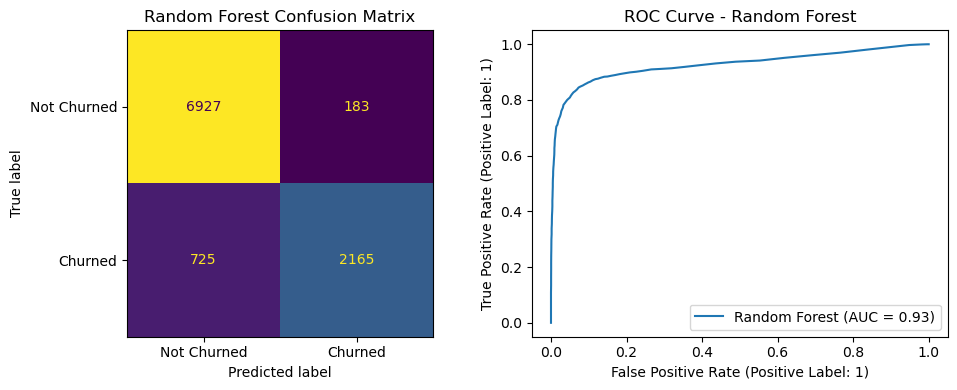

In [4]:
# Create two graphs side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

y_pred = rf_model.predict(X_test)

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Churned", "Churned"]
)

disp.plot(ax=ax1, colorbar=False)
ax1.set_title("Random Forest Confusion Matrix")

# Get prediction probabilities
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Calculate ROC and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

# Plot ROC Curve
ax2.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc:.2f})")

ax2.set_xlabel("False Positive Rate (Positive Label: 1)")
ax2.set_ylabel("True Positive Rate (Positive Label: 1)")
ax2.set_title("ROC Curve - Random Forest")
ax2.legend()

# Adjust spacing
plt.tight_layout()
plt.show()

In [5]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=3))

# Evaluate the model
print("Accuracy:", f"{accuracy_score(y_test, y_pred):.3f}")

# Display AUC score
print("AUC Score:", f"{roc_auc:.3f}")


Classification Report:
              precision    recall  f1-score   support

           0      0.905     0.974     0.938      7110
           1      0.922     0.749     0.827      2890

    accuracy                          0.909     10000
   macro avg      0.914     0.862     0.883     10000
weighted avg      0.910     0.909     0.906     10000

Accuracy: 0.909
AUC Score: 0.926


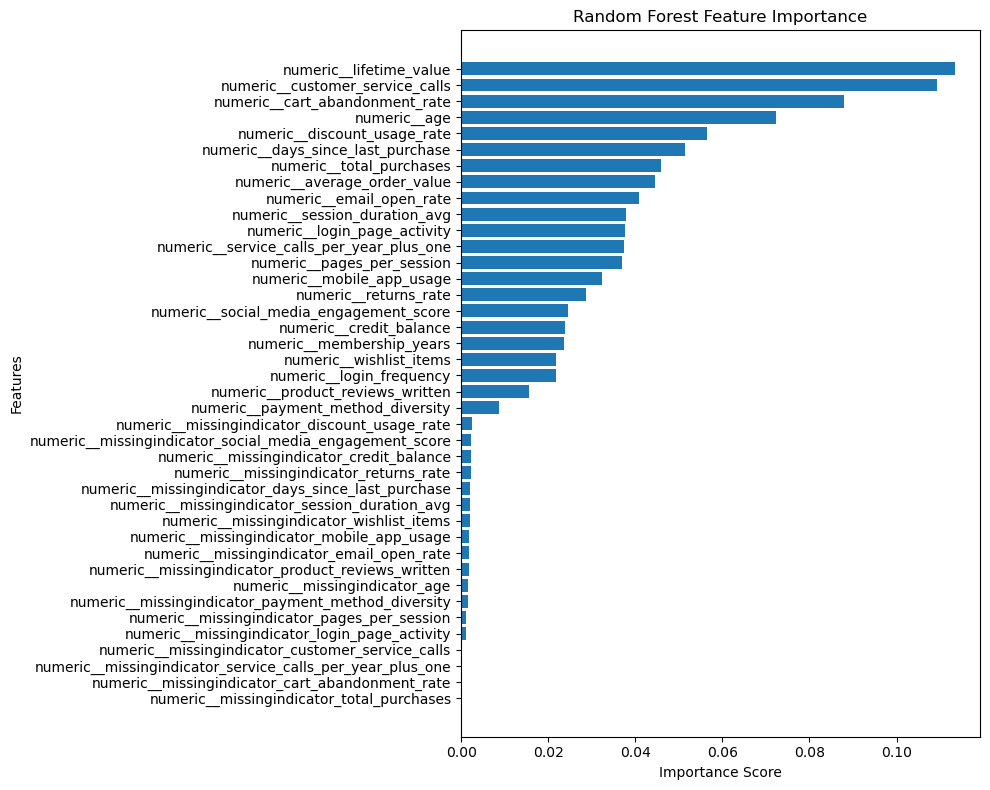

In [10]:
# Get feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Plot feature importance
plt.figure(figsize=(10, 8))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()